Feature matrix shape: (9333, 29)
Hourly model → R²=0.952, MAE=0.182
Daily model → R²=-0.368, MAE=0.713


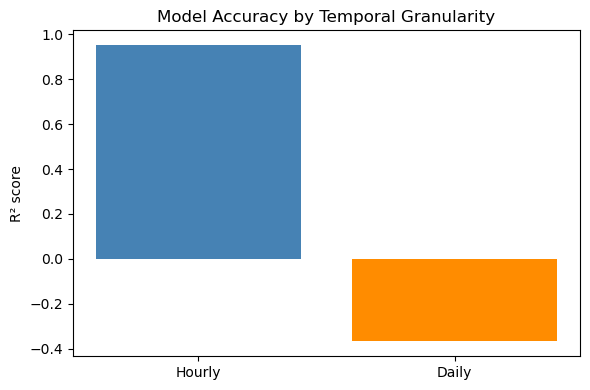

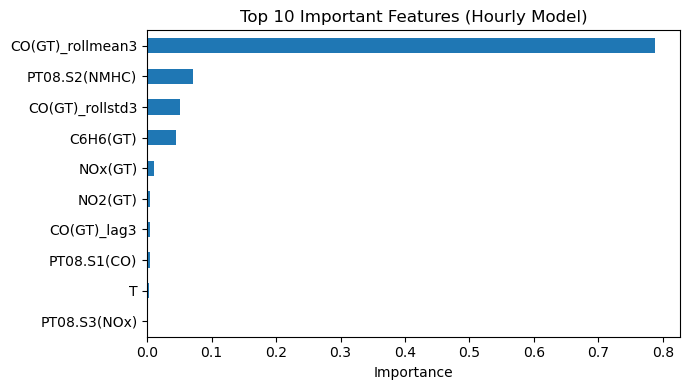

In [1]:
# =====================================================
# COMP9417 Air Quality Project
# STEP 5 — FEATURE ENGINEERING
# =====================================================
# Creates lagged and rolling features to model temporal dependencies
# and compares hourly vs. daily aggregates.
# =====================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

# ---------- 1. Load cleaned data ----------
df = pd.read_csv("AirQuality_clean.csv", parse_dates=["timestamp"]).sort_values("timestamp")
df = df.set_index("timestamp")

# ---------- 2. Example target ----------
target = "CO(GT)"  # predict next-hour CO concentration
assert target in df.columns, f"{target} not found in dataset!"

# ---------- 3. Create lagged features ----------
LAGS = [1, 3, 6, 12, 24]  # hours
for lag in LAGS:
    df[f"{target}_lag{lag}"] = df[target].shift(lag)

# ---------- 4. Rolling statistics (short/long-term trends) ----------
WINDOWS = [3, 6, 24]  # hours
for w in WINDOWS:
    df[f"{target}_rollmean{w}"] = df[target].rolling(window=w).mean()
    df[f"{target}_rollstd{w}"]  = df[target].rolling(window=w).std()

# ---------- 5. Temporal encodings ----------
df["hour"]    = df.index.hour
df["weekday"] = df.index.dayofweek
df["month"]   = df.index.month
df["is_weekend"] = df["weekday"].isin([5, 6]).astype(int)

# Drop early rows with NaNs from rolling/lags
df_feat = df.dropna().copy()
print("Feature matrix shape:", df_feat.shape)

# ---------- 6. Baseline model (hourly) ----------
# numeric-only feature set (avoid Date/Time strings)
num_cols = df_feat.select_dtypes(include=[np.number]).columns
features = [c for c in num_cols if c != target]

X = df_feat[features].replace([np.inf, -np.inf], np.nan).dropna()
y = df_feat.loc[X.index, target]  # align indices after dropna

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, shuffle=False
)

rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

# Evaluate hourly model
y_pred = rf.predict(X_test)
r2_hourly = r2_score(y_test, y_pred)
mae_hourly = mean_absolute_error(y_test, y_pred)
print(f"Hourly model → R²={r2_hourly:.3f}, MAE={mae_hourly:.3f}")


# ---------- 7. Aggregate to daily granularity ----------
# Resample numeric-only columns to avoid object-dtype aggregation errors
numcols = df.select_dtypes(include=[np.number]).columns
daily = df[numcols].resample("D").mean()

# Next-day target
daily["CO_next"] = daily[target].shift(-1)

# Daily lags/rolls on the target
for lag in [1, 3, 7]:
    daily[f"{target}_lag{lag}d"] = daily[target].shift(lag)
for w in [3, 7]:
    daily[f"{target}_rollmean{w}d"] = daily[target].rolling(window=w, min_periods=w).mean()

# Drop rows with NaNs introduced by shift/rolling
daily = daily.dropna()

# Numeric-only features/labels for modeling
X_day = daily.drop(columns=["CO_next"])
y_day = daily["CO_next"]

# Guard against infs/NaNs
X_day = X_day.replace([np.inf, -np.inf], np.nan).dropna()
y_day = y_day.loc[X_day.index]

# Train & evaluate daily model
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    X_day, y_day, test_size=0.2, shuffle=False
)
rf_day = RandomForestRegressor(n_estimators=100, random_state=42)
rf_day.fit(Xd_train, yd_train)
y_day_pred = rf_day.predict(Xd_test)

r2_daily = r2_score(yd_test, y_day_pred)
mae_daily = mean_absolute_error(yd_test, y_day_pred)
print(f"Daily model → R²={r2_daily:.3f}, MAE={mae_daily:.3f}")

# ---------- 8. Compare temporal granularity ----------
plt.figure(figsize=(6,4))
plt.bar(["Hourly","Daily"], [r2_hourly, r2_daily], color=["steelblue","darkorange"])
plt.ylabel("R² score")
plt.title("Model Accuracy by Temporal Granularity")
plt.tight_layout()
plt.show()

# ---------- 9. Feature importance visualization ----------
importances = pd.Series(rf.feature_importances_, index=X.columns)
top_imp = importances.sort_values(ascending=False).head(10)

plt.figure(figsize=(7,4))
top_imp.plot(kind="barh")
plt.gca().invert_yaxis()
plt.title("Top 10 Important Features (Hourly Model)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()


h=3 → R²=0.548, MAE=0.690
h=6 → R²=0.540, MAE=0.698
h=12 → R²=0.399, MAE=0.844
h=24 → R²=0.203, MAE=0.987
   horizon_hr        R2       MAE
0           3  0.548107  0.690285
1           6  0.539670  0.697572
2          12  0.398764  0.843999
3          24  0.202686  0.987187


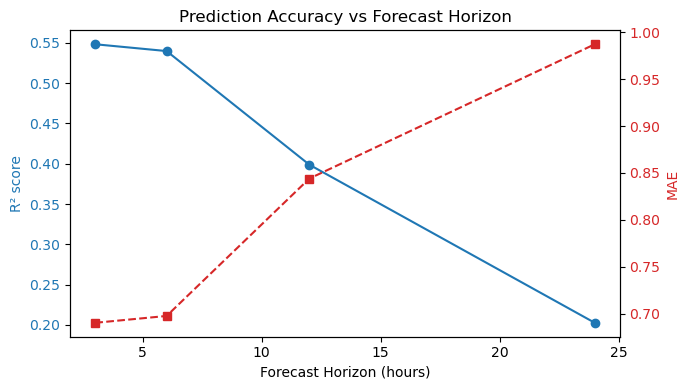

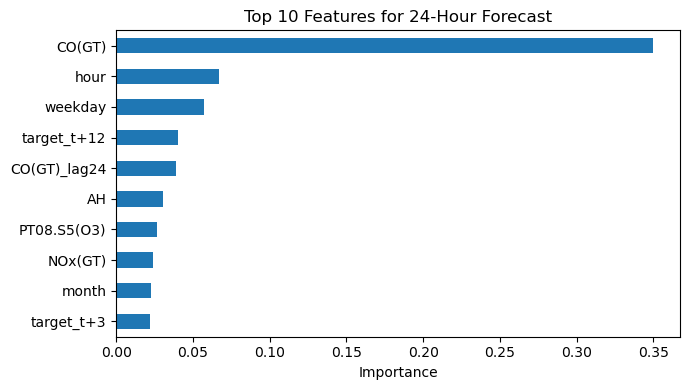

In [2]:
# =====================================================
# COMP9417 Air Quality Project
# STEP 5B — MULTI-STEP FORECASTING
# =====================================================
# Evaluates prediction accuracy for multiple horizons:
#   CO(t+3h), CO(t+6h), CO(t+12h), CO(t+24h)
# =====================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error

# ---------- 1. Reload cleaned data ----------
df = pd.read_csv("AirQuality_clean.csv", parse_dates=["timestamp"]).sort_values("timestamp")
df = df.set_index("timestamp")

target = "CO(GT)"
assert target in df.columns, f"{target} not found"

# ---------- 2. Base lag & rolling features ----------
LAGS = [1,3,6,12,24]
for lag in LAGS:
    df[f"{target}_lag{lag}"] = df[target].shift(lag)

WINDOWS = [3,6,24]
for w in WINDOWS:
    df[f"{target}_rollmean{w}"] = df[target].rolling(w).mean()
    df[f"{target}_rollstd{w}"]  = df[target].rolling(w).std()

df["hour"] = df.index.hour
df["weekday"] = df.index.dayofweek
df["month"] = df.index.month
df["is_weekend"] = df["weekday"].isin([5,6]).astype(int)

df = df.dropna().copy()

# ---------- 3. Forecast horizons ----------
horizons = [3, 6, 12, 24]  # hours ahead
results = []

# (optional) explicitly drop any raw string cols if they exist
df = df.drop(columns=["Date", "Time"], errors="ignore")

for h in horizons:
    tgt_col = f"target_t+{h}"
    df[tgt_col] = df[target].shift(-h)

    # keep rows where the shifted target exists
    df_h = df.dropna(subset=[tgt_col]).copy()

    # NUMERIC-ONLY features to avoid '11/03/2004' style strings
    num_cols = df_h.select_dtypes(include=[np.number]).columns
    feat_cols = [c for c in num_cols if c != tgt_col]  # exclude target

    X = df_h[feat_cols].replace([np.inf, -np.inf], np.nan).dropna()
    y = df_h.loc[X.index, tgt_col]  # align indices after dropna

    # Guardrail: skip if not enough rows
    if len(X) < 100:
        print(f"Skipping horizon {h}: too few samples after cleaning ({len(X)} rows).")
        continue

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, shuffle=False
    )

    model = RandomForestRegressor(n_estimators=150, random_state=42)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    results.append((h, r2, mae))
    print(f"h={h} → R²={r2:.3f}, MAE={mae:.3f}")


# ---------- 4. Results summary ----------
res_df = pd.DataFrame(results, columns=["horizon_hr","R2","MAE"])
print(res_df)

# ---------- 5. Plot performance vs horizon ----------
fig, ax1 = plt.subplots(figsize=(7,4))
ax1.plot(res_df["horizon_hr"], res_df["R2"], "o-", label="R²")
ax1.set_xlabel("Forecast Horizon (hours)")
ax1.set_ylabel("R² score", color="tab:blue")
ax1.tick_params(axis="y", labelcolor="tab:blue")

ax2 = ax1.twinx()
ax2.plot(res_df["horizon_hr"], res_df["MAE"], "s--", color="tab:red", label="MAE")
ax2.set_ylabel("MAE", color="tab:red")
ax2.tick_params(axis="y", labelcolor="tab:red")

plt.title("Prediction Accuracy vs Forecast Horizon")
fig.tight_layout()
plt.show()

# ---------- 6. Optional: feature importance for longest horizon ----------
longest_h = horizons[-1]
df_long = df.dropna(subset=[target])
df_long[f"target_t+{longest_h}"] = df_long[target].shift(-longest_h)
df_long = df_long.dropna()
X_long = df_long.drop(columns=[f"target_t+{longest_h}"])
y_long = df_long[f"target_t+{longest_h}"]

rf_long = RandomForestRegressor(n_estimators=150, random_state=42)
rf_long.fit(X_long, y_long)
importances = pd.Series(rf_long.feature_importances_, index=X_long.columns)
top_imp = importances.sort_values(ascending=False).head(10)

plt.figure(figsize=(7,4))
top_imp.plot(kind="barh")
plt.gca().invert_yaxis()
plt.title(f"Top 10 Features for {longest_h}-Hour Forecast")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()
